Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Feature Importance:
             Feature  Importance
2  petal length (cm)    0.440338
3   petal width (cm)    0.439591
0  sepal length (cm)    0.114307
1   sepal width (cm)    0.005764


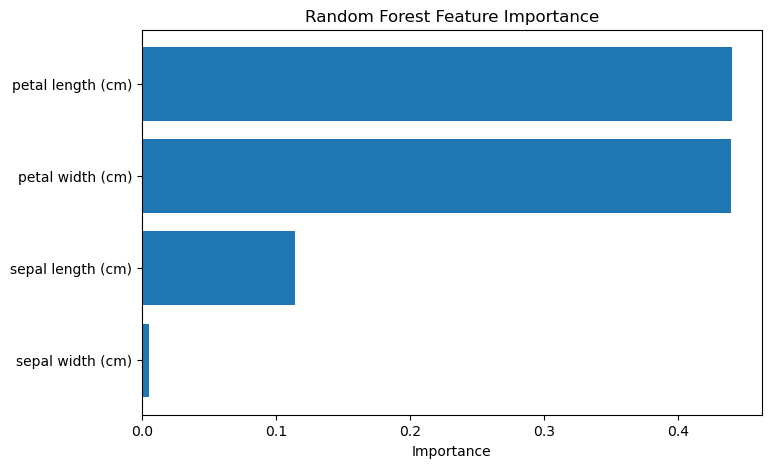

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
iris = load_iris()

X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=3,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluate model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Feature Importance
importance = pd.DataFrame({
    "Feature": iris.feature_names,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
print(importance)

# Visualize Feature Importance
plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.show()

In [2]:
# Random Forest Classifier
# Train multiple decision trees and combine their predictions using majority voting.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]


Trees: 1, Accuracy: 0.9667
Trees: 5, Accuracy: 0.9333
Trees: 10, Accuracy: 0.9667
Trees: 20, Accuracy: 0.9333
Trees: 50, Accuracy: 0.9000
Trees: 100, Accuracy: 0.9000
Trees: 200, Accuracy: 0.9000
Trees: 300, Accuracy: 0.9000


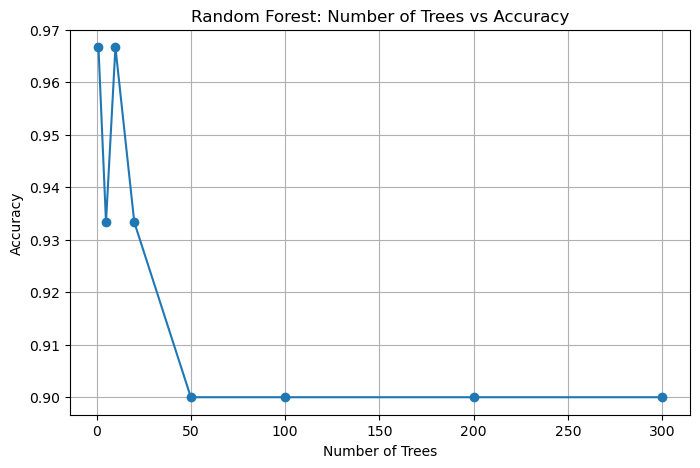

In [3]:
# Random Forest: Effect of n_estimators
# Compare model accuracy using different numbers of decision trees.

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

tree_values = [1, 5, 10, 20, 50, 100, 200, 300]

results = []

for n in tree_values:

    model = RandomForestClassifier(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append(accuracy)

    print(f"Trees: {n}, Accuracy: {accuracy:.4f}")

# Visualize results
plt.figure(figsize=(8, 5))
plt.plot(tree_values, results, marker="o")

plt.xlabel("Number of Trees")
plt.ylabel("Accuracy")
plt.title("Random Forest: Number of Trees vs Accuracy")
plt.grid(True)
plt.show()

             Feature  Importance
2  petal length (cm)    0.450316
3   petal width (cm)    0.409548
0  sepal length (cm)    0.121454
1   sepal width (cm)    0.018682


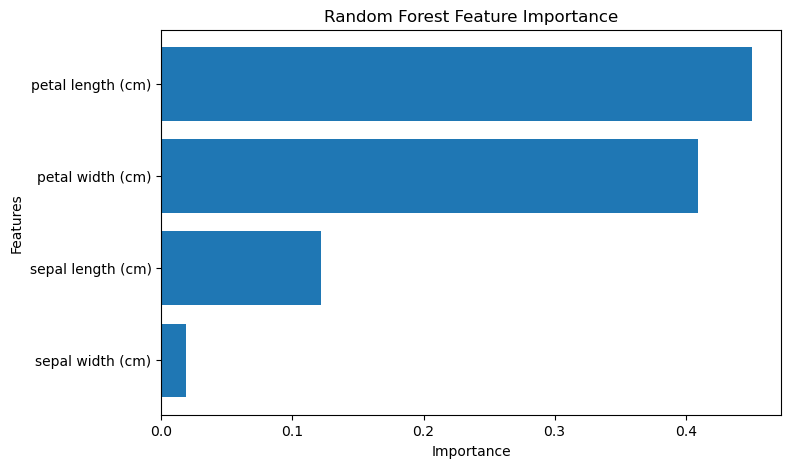

In [4]:
# Random Forest Feature Importance
# Identify and visualize the most important input features.

importance = model.feature_importances_

feature_df = pd.DataFrame({
    "Feature": iris.feature_names,
    "Importance": importance
})

feature_df = feature_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_df)

plt.figure(figsize=(8, 5))

plt.barh(
    feature_df["Feature"],
    feature_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.show()

In [5]:
# Random Forest Regressor
# Predict a continuous numerical value using multiple decision trees.

from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Load dataset
data = load_diabetes()

X = data.data
y = data.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Create model
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluation
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 44.053033707865175
MSE: 2952.0105887640448
RMSE: 54.332408273184846
R2 Score: 0.4428225673999313


### difference between bagging and random forest

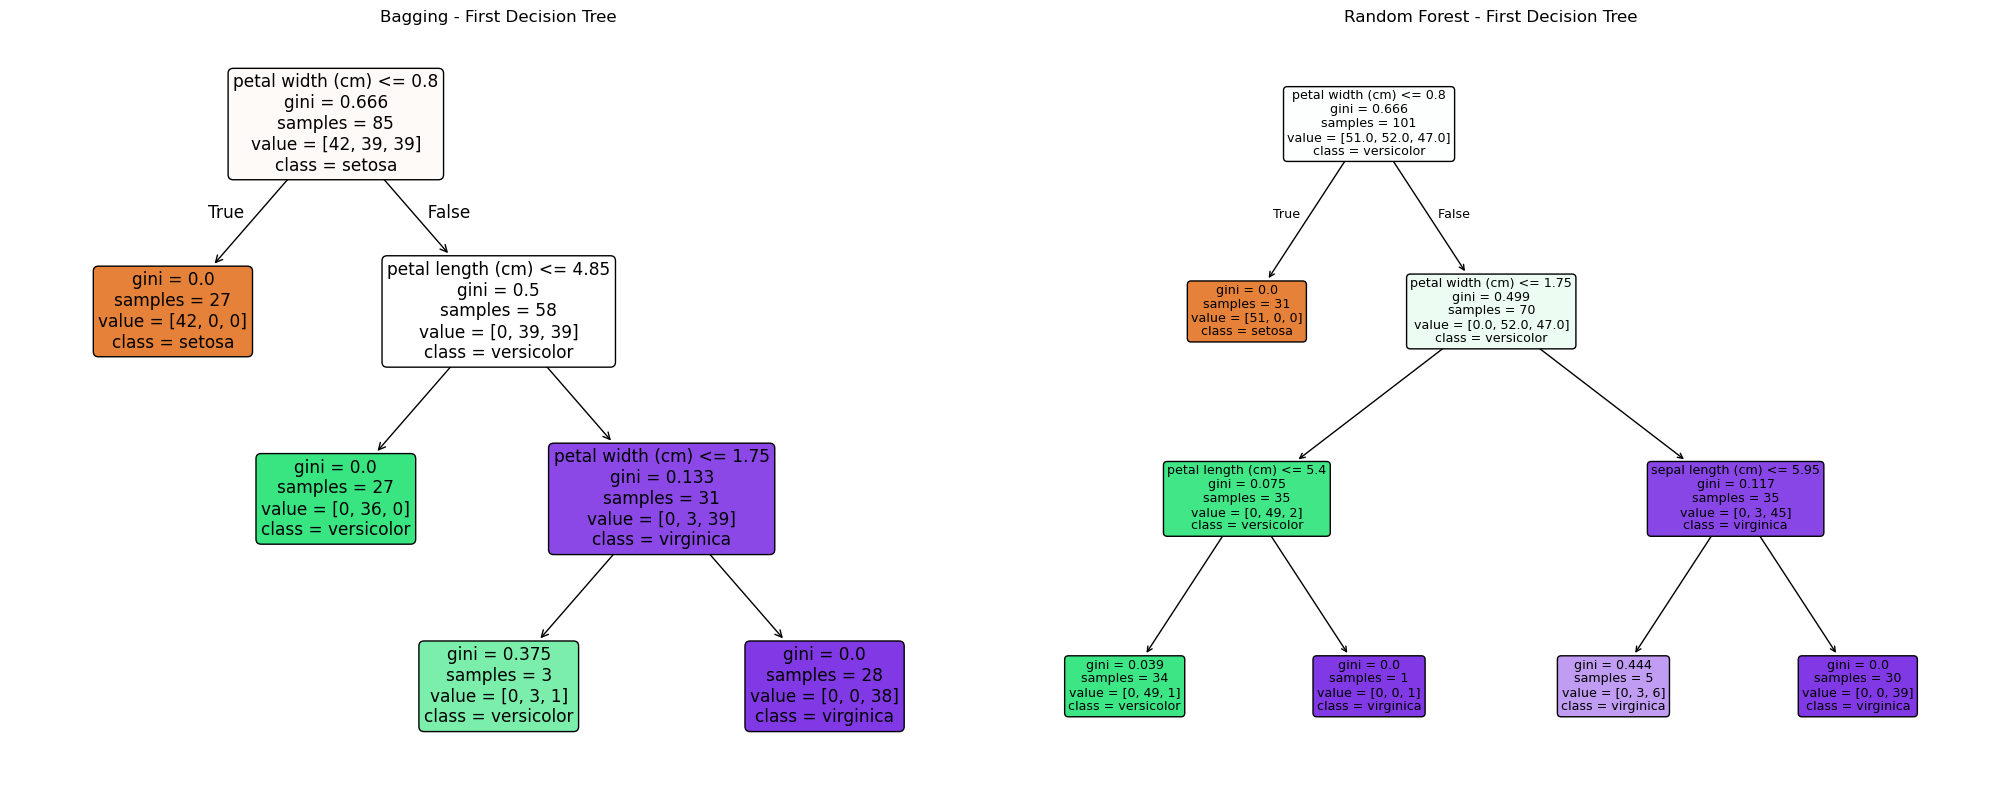

In [6]:
# Bagging vs Random Forest: Feature Selection Visualization
# Compare which features are considered at every split of each decision tree.

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.tree import plot_tree

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

feature_names = iris.feature_names

# Create Bagging model
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ),
    n_estimators=3,
    max_samples=0.8,
    max_features=1.0,
    bootstrap=True,
    random_state=42
)

# Create Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=3,
    max_depth=3,
    max_features=2,
    bootstrap=True,
    random_state=42
)

# Train both models
bagging.fit(X, y)
random_forest.fit(X, y)

# Visualize first tree from each model
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

plot_tree(
    bagging.estimators_[0],
    feature_names=feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    ax=axes[0]
)

axes[0].set_title("Bagging - First Decision Tree")

plot_tree(
    random_forest.estimators_[0],
    feature_names=feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    ax=axes[1]
)

axes[1].set_title("Random Forest - First Decision Tree")

plt.tight_layout()
plt.show()

In [7]:
# Feature Selection at Every Decision Tree Split
# Display all candidate features for Bagging and selected features for Random Forest.

def show_feature_selection(model, model_name, feature_names):

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    for tree_number, tree in enumerate(model.estimators_):

        print(f"\nDecision Tree {tree_number + 1}")

        tree_model = tree.tree_

        for node in range(tree_model.node_count):

            # Skip leaf nodes
            if tree_model.children_left[node] == tree_model.children_right[node]:
                continue

            selected_feature = tree_model.feature[node]

            if model_name == "Bagging":
                candidates = feature_names
            else:
                # sklearn's RandomForest uses max_features candidates
                # at each split, but does not expose the exact candidate
                # subset in the fitted tree.
                candidates = "2 randomly selected features (not exposed by sklearn)"

            print(f"\nSplit Node: {node}")
            print(f"Candidate Features: {candidates}")
            print(f"Actual Split Feature: {feature_names[selected_feature]}")
            print(f"Threshold: {tree_model.threshold[node]:.2f}")


show_feature_selection(bagging, "Bagging", feature_names)

show_feature_selection(random_forest, "Random Forest", feature_names)


Bagging

Decision Tree 1

Split Node: 0
Candidate Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Actual Split Feature: petal width (cm)
Threshold: 0.80

Split Node: 2
Candidate Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Actual Split Feature: petal length (cm)
Threshold: 4.85

Split Node: 4
Candidate Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Actual Split Feature: petal width (cm)
Threshold: 1.75

Decision Tree 2

Split Node: 0
Candidate Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Actual Split Feature: petal length (cm)
Threshold: 2.45

Split Node: 2
Candidate Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Actual Split Feature: petal width (cm)
Threshold: 1.70

Split Node: 3
Candidate Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length

### hyperparameter tuning

In [8]:
# Random Forest Hyperparameter Tuning
# Load the Iris dataset and prepare training and testing data.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (120, 4)
Testing shape: (30, 4)


Max Features: sqrt, Accuracy: 0.9000
Max Features: log2, Accuracy: 0.9000
Max Features: None, Accuracy: 0.9667
Max Features: 0.5, Accuracy: 0.9000
Max Features: 0.75, Accuracy: 0.9333
Max Features: 1.0, Accuracy: 0.9667


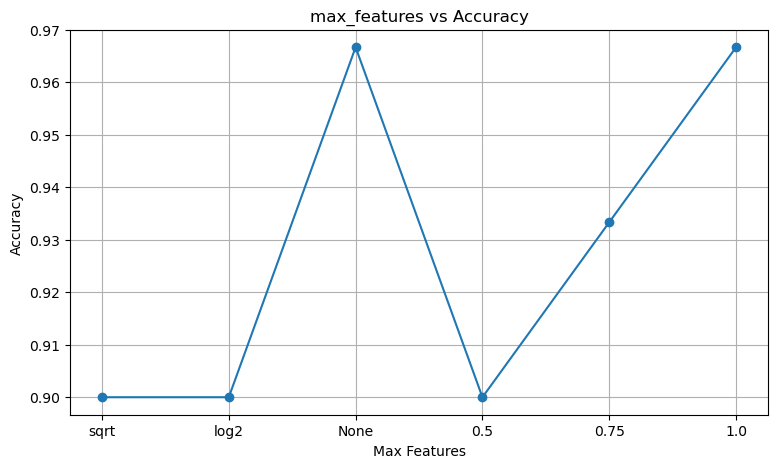

In [9]:
# Tune max_features in Random Forest
# Compare feature-selection strategies and their test accuracy.

feature_values = ["sqrt", "log2", None, 0.5, 0.75, 1.0]

results = []

for feature in feature_values:

    model = RandomForestClassifier(
        n_estimators=100,
        max_features=feature,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append(accuracy)

    print(f"Max Features: {feature}, Accuracy: {accuracy:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(
    [str(x) for x in feature_values],
    results,
    marker="o"
)

plt.xlabel("Max Features")
plt.ylabel("Accuracy")
plt.title("max_features vs Accuracy")
plt.grid(True)
plt.show()

In [10]:
# Random Forest GridSearchCV
# Find the best hyperparameter combination using 5-fold cross-validation.

from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 10],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

# Train and search
grid_search.fit(X_train, y_train)

# Best parameters
print("Best Parameters:")
print(grid_search.best_params_)

# Best cross-validation score
print("\nBest CV Accuracy:")
print(grid_search.best_score_)

# Evaluate on test data
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("\nTest Accuracy:")
print(accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Best Parameters:
{'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best CV Accuracy:
0.9583333333333334

Test Accuracy:
0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



Exception ignored in: <function ResourceTracker.__del__ at 0x10676dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104d39bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104ff5bc0>
Traceback (most recent call last

In [11]:
# Random Forest RandomizedSearchCV
# Search randomly selected hyperparameter combinations to reduce tuning time.

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

param_dist = {
    "n_estimators": randint(50, 500),
    "max_depth": [None, 3, 5, 10, 15, 20],
    "max_features": ["sqrt", "log2", None],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 10)
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV Accuracy:")
print(random_search.best_score_)

best_random_model = random_search.best_estimator_

y_pred = best_random_model.predict(X_test)

print("\nTest Accuracy:")
print(accuracy_score(y_test, y_pred))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 13, 'n_estimators': 363}

Best CV Accuracy:
0.9583333333333334

Test Accuracy:
0.9666666666666667


Exception ignored in: <function ResourceTracker.__del__ at 0x105271bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x102f1dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106869bc0>
Traceback (most recent call last

In [12]:
# Random Forest RandomizedSearchCV
# Search randomly selected hyperparameter combinations to reduce tuning time.

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

param_dist = {
    "n_estimators": randint(50, 500),
    "max_depth": [None, 3, 5, 10, 15, 20],
    "max_features": ["sqrt", "log2", None],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 10)
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV Accuracy:")
print(random_search.best_score_)

best_random_model = random_search.best_estimator_

y_pred = best_random_model.predict(X_test)

print("\nTest Accuracy:")
print(accuracy_score(y_test, y_pred))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 13, 'n_estimators': 363}

Best CV Accuracy:
0.9583333333333334

Test Accuracy:
0.9666666666666667


Exception ignored in: <function ResourceTracker.__del__ at 0x106eb1bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104dcdbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x107251bc0>
Traceback (most recent call last